# Supplementary Fig. 6c: features of the synthetic simulations and of our biophysical model

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel c of Supplementary Fig. 6: distributions over ground truth neurons of macroscopic (cell-to-site and cell-to-cell distances, firing rate and range, SNR, amplitude) and waveform (MAD ratio, peak-to-valley, repolarization slope, exponential decay, spread, velocities) features in Buccino's synthetic model (2020) and in the MEArec models S2 to S5 (blue), which are increasingly constrained to match our biophysical model of the spontaneous regime (red). 'Matched' marks the features that a model is constrained to match. Source data and svg are saved in figures/8_source_data/supp_fig6c/.

**data** (first 10 minutes of each simulation)
* Buccino 2020: `dataset/00_raw/recording_buccino` and `sorting_buccino` (ground truth, 250 neurons)
* S2 to S5: simulated with MEArec 1.8.0 and the parameters of the paper (`src/pipes/validation/synthetic/simulate_mearec.py`); their spike trains and soma positions are those of the paper's S2 on DANDI (dandiset 001250, `sub-mearec-synthetics-s2`) and their traces differ from it by 2 uV rms (5% of the signal rms)
* biophysical model: `dataset/00_raw/recording_npx_spont` (int16, 300 Hz high-pass, median common reference) and `ground_truth_npx_spont` (1,388 neurons)
* features: `src/pipes/validation/synthetic/compute_features.py` (spikeinterface 0.103, waveforms of at most 500 spikes per neuron within 100 um of the nearest site); neurons without spike in the 10 minutes have no waveform features and are not shown

## Prerequisites

The features of this figure are in `dataset/01_intermediate/supplementary/synthetic_features/*.npz`. To recompute them from scratch (about 1 hour 30 minutes, 85 GB of temporary disk, GPU for the sorting), run from the repository root:

```bash
python src/pipes/validation/synthetic/run_all.py all
```

The script simulates S2-S5 with MEArec 1.8.0 (the version of the paper: its filter step adds the filtered traces to the unfiltered ones, so spikes are 1.73 times larger than with the 1.9.0 of the environment), computes the features and spike sorts S2-S5 with Kilosort4. Its steps can be run alone (`install`, `simulate`, `features`, `sort`).

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import synthetic_features_plots as plots

# features computed by src/pipes/validation/synthetic/compute_features.py
FEATURES_PATH = "dataset/01_intermediate/supplementary/synthetic_features/"
MODELS = ["buccino", "s2", "s3", "s4", "s5"]
FEATURES = [row[0] for row in plots.FEATURE_ROWS]

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.8
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the features

In [2]:
F = {m: dict(np.load(FEATURES_PATH + f"{m}.npz")) for m in MODELS + ["ns"]}
rows = []
for m in MODELS + ["ns"]:
    d = pd.DataFrame({f: F[m][f] for f in FEATURES})
    d.insert(0, "unit", np.arange(len(d)))
    d.insert(0, "model", "biophysical (NS)" if m == "ns" else m)
    rows.append(d)
df = pd.concat(rows, ignore_index=True)
display(df.groupby("model")[FEATURES].median().loc[["biophysical (NS)"] + MODELS].T.apply(lambda c: c.map(lambda x: f"{x:.3g}")))

model,biophysical (NS),buccino,s2,s3,s4,s5
cell_to_site_distance,33.4,38.6,36.8,36.8,36.8,34.5
cell_distance,14.1,34.3,15.2,15.2,15.2,15.3
firing_rates,0.04,5.35,5.04,0.293,0.315,0.315
firing_ranges,0.2,3.21,3.2,0.705,0.8,0.8
snrs,3.59,6.45,5.02,7.46,12.1,12
amplitudes,-7,-103,-185,-197,-195,-197
mad_ratios,1,0.581,0.703,0.454,0.419,0.425
peak_to_valley,0.000878,0.00135,0.00134,0.00128,0.00134,0.00133
repolarization_slope,2.62e+04,1.74e+05,3.15e+05,3.05e+05,3.02e+05,3.03e+05
exp_decay,0.0459,0.0228,0.0284,0.0287,0.0285,0.0291


## Plot, same as the paper's panel c

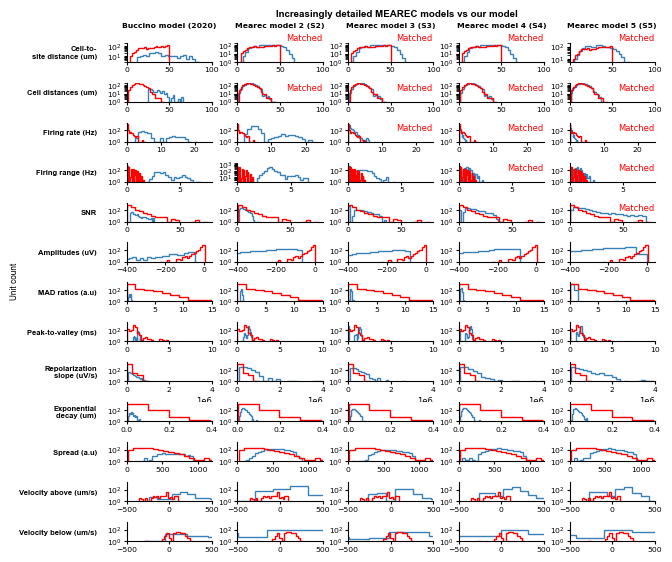

In [3]:
def plot_source_data(df: pd.DataFrame):
    """Distributions of the features of each model (blue) and of the biophysical model (red)"""
    features = {m: {f: d[f].values for f in FEATURES} for m, d in df.groupby("model")}
    features_ns = features.pop("biophysical (NS)")
    return plots.plot_features_figure(features, features_ns)


fig, axes = plot_source_data(df)

## Save the figure and the source data

In [4]:
os.makedirs("figures/8_source_data/supp_fig6c", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig6c/supp_fig6c.svg", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig6c/supp_fig6c.xlsx", index=False)

<Figure size 640x480 with 0 Axes>

## Check: replot from the saved source data

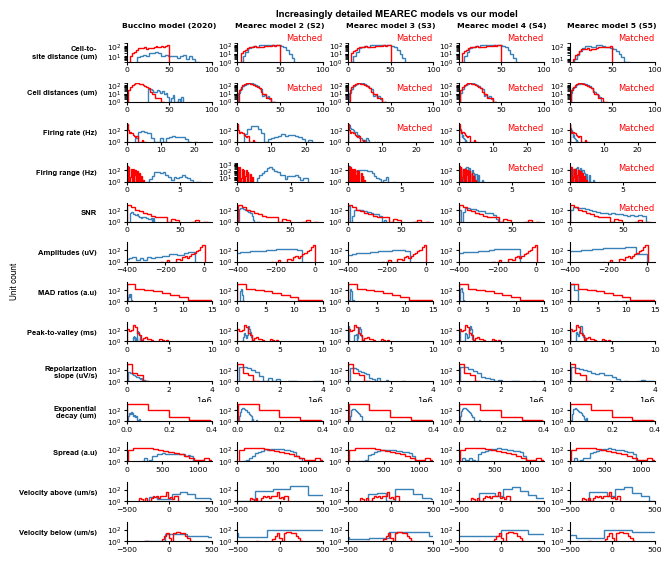

In [5]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig6c/supp_fig6c.xlsx")
fig, axes = plot_source_data(df_loaded)